# Seismic Processing Warmup. Teapot Dome 2D Line A

**Author:** Owen

**Dataset:** Teapot Dome 3D Survey (land, Wyoming), Line A : public domain, released by US Dept. of Energy via RMOTC, mirrored by (https://github.com/softwareunderground/TeapotDome/blob/master/source/2D_Seismic/NormalizedMigrated_segy/lineA.sgy)

**Format:** SEG-Y (2D post-stack)

**Tool:** `segyio`, `numpy`, `scipy.signal`, `matplotlib`

## Purpose

I had no prior seismic processing experience when starting this notebook. The goal was to walk through the fundamental read -> inspect -> process -> attribute pipeline on a real public SEG-Y file and build baseline literacy in the domain. This icnludes the data format, frequency content, the standard filter, and one attribute (envelope).

## What this notebook demonstrates

1. Loading and inspecting a SEG-Y file with `segyio`
2. Visualising a 2D seismic section with appropriate colour clipping
3. Extract a single trace and computing its frequency spectrum via FFT
4. Designing and validating a Butterworth bandpass filter via synthetic noise injection
5. Computing the envelope attribute via Hilbert transform
6. Side by side comparison : raw/ filtered/ envelope sections

## Key observation

Teapot Dome has already been shaped during prior processing. The data is natively band-limited to ~10-55 Hz. Applying a 10-55 Hz bandpass to the raw data therefore produced minimal visible change. To verify the filter actually works, I injected synthetic low-frequency drift and high-frequency hiss into one trace and demonstrated clean removal.

--

## Phase 1 : Load and inspect the SEG-Y file

Open with `ignore_gemotry=True` because we are working with a single 2D seismic line, (no 3D crossline grid to reconstruct). Setting `strict=False` serves as a safeguard to tolerate non-standard or slightly irregular SEG-Y headers commonly found in real-world datasets.

Together, these settings allow us to load the raw traces directly into a 2D array for fast processing.

In [1]:
import segyio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PATH = Path("teapot.sgy") / "lineA.sgy"

In [2]:
with segyio.open(PATH, "r", ignore_geometry=True, strict=False) as f: #ign_geo=True : SEG-Y files have an underlying grid, and segyio tries to reconstruct that grid on open. We just want to treat this as a flat list of traces in 2D.
    n_traces = f.tracecount
    n_samples = len(f.samples)
    sample_rate_ms = segyio.tools.dt(f) / 1000 # turn microsec to millisec

print (f"Traces: {n_traces}")
print (f"Samples per trace: {n_samples}")
print (f"Sample rate: {sample_rate_ms} ms")
print (f"Total record time: {sample_rate_ms * n_samples:.0f} ms")

#We found :
#390 Traces = 390 spatial positions along a line ont he ground, each one a cleaned best estimate of whats underground directly below that spot
#1001 Data points per trace
#We kept the microphones listening for 4004 ms after each blast fired
#Shallow reflection come back fast (~500ms). Deep reflection longer (~2000ms+)

Traces: 390
Samples per trace: 1001
Sample rate: 4.0 ms
Total record time: 4004 ms


In [3]:
with segyio.open(PATH, "r", ignore_geometry=True, strict=False) as f:
    traces = f.trace.raw[:]

print (f"Traces array shape: {traces.shape}")
print (f"Amplitude range {traces.min():.2f} to {traces.max():.2f}")

Traces array shape: (390, 1001)
Amplitude range -6.42 to 6.62


### 2D section visualisation

Each trace is one vertical column, two-way time runs downward. Red/blue stripes = rock layer boundaries (reflections). The `vm = 0.5 * std` clip controls colour contrast - tighter clipping lets the layered structure stand out instead of washing gray.

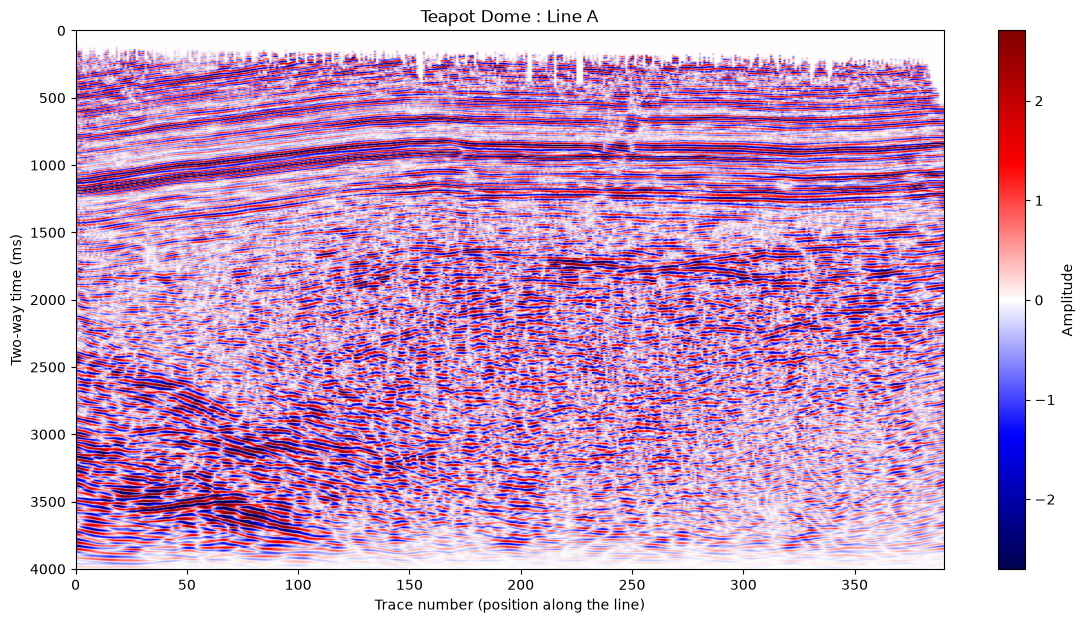

In [4]:
section = traces.T   #.T is transpose, flip the array axes. We swap because imshow draws arrays with rows going DOWN the page. 
#In seismic, time runs vertically. We need time on row axis
vm = 3 * np.std(section) 

plt.figure(figsize = (14,7))
plt.imshow(section, cmap = "seismic", vmin = -vm, vmax = vm, aspect = "auto",
           extent = [0, section.shape[1], section.shape[0]*sample_rate_ms, 0])
plt.xlabel("Trace number (position along the line)")
plt.ylabel("Two-way time (ms)")
plt.title("Teapot Dome : Line A")
plt.colorbar(label="Amplitude")
plt.show()

## Phase 2 - Frequency content and bandpass filter

Pull one trace out of the 2D section and look at it as a 1D waveform.
Then FFT it to see which frequencies the signal is actually made of, that determines where to place the bandpass cutoffs

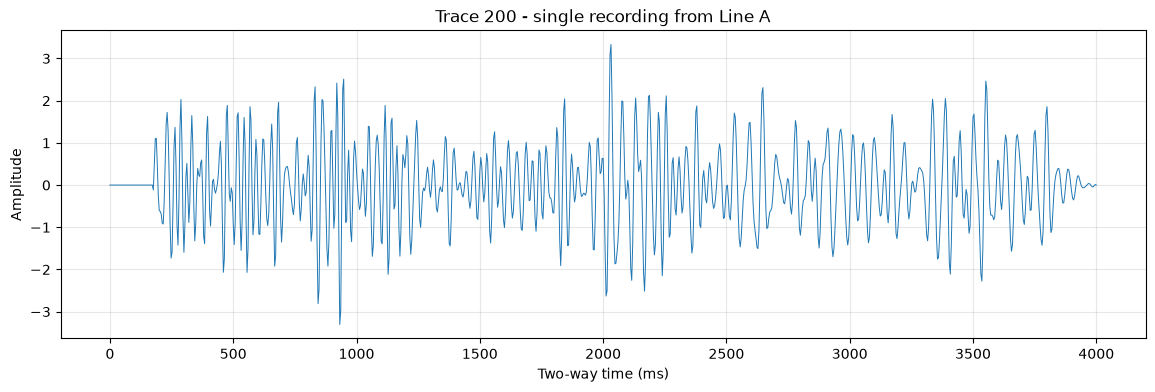

In [5]:
#Now look at the frequency content, then filter
#Pul one trace out and plot it as a waveform

trace_idx = 200     # a spot roughly in the middle of the line
trace = traces[trace_idx]

time_ms = np.arange(n_samples) * sample_rate_ms

plt.figure(figsize=(14,4))
plt.plot(time_ms, trace, lw = 0.7)
plt.xlabel("Two-way time (ms)")
plt.ylabel("Amplitude") #amplitude : how strong the echo was from that depth. A loud section = many strong rock boundary reflection stacked together
#A quiet section = fewer boundaries, or a thick homogenous rock mass that doesn reflect much.
plt.title(f"Trace {trace_idx} - single recording from Line A")
plt.grid(alpha=0.3)
plt.show()

#What this does :
#Take one vert column out of our 2D section (position #200 along the line)
#Unroll it , and plot it as a wiggly line
#Same object as one column of the 2D image, just viewed sideways
#Big wiggles = strong reflections
#Small jitter between them = noise + weak reflections



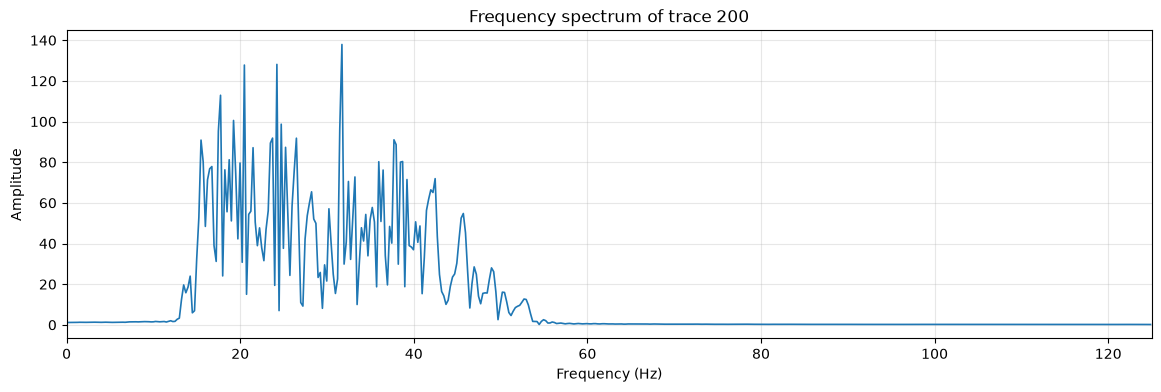

In [6]:
#FFT : what frequencies is this signal made of?

from scipy.fft import rfft, rfftfreq

dt_s = sample_rate_ms / 1000 #sample interval in seconds

spectrum = np.abs(rfft(trace))
freqs = rfftfreq(n_samples, d=dt_s)

plt.figure(figsize = (14,4))
plt.plot(freqs, spectrum, lw = 1.2)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title(f"Frequency spectrum of trace {trace_idx}")
plt.xlim(0,125) #Nyquist = half the sample rate = 125 Hz for 4ms sampling
plt.grid(alpha=0.3)
plt.show()

# What FFT does :
# Our trace is a wiggly line in Time.
# So FFT takes it apart and says "our signal is made of this much 20 Hz + this much 30 Hz, etc."
# A pure sine wave would show as one huge spike
# But a seismic trace shows a broad hump where most of its energy lives in one frequency range. Fall of at extremes

**Observation:** signal lives between 12 & 55 Hz with a dominant peak around 30-35 Hz. Basically no energy below 10 Hz or above 60 Hz. Bandpass cutoffs at **10-55 Hz**.

### Bandpass filter design

4th-order Butterworth bandpass using `scipy.signal`, applied with `filtfilt` (zero-phase filtering - preserves reflection timing, which matters for later interpretation)

In [7]:
#Apply bandpass filter to every trace

from scipy.signal import butter, filtfilt

def bandpass (data, lowcut, highcut, fs, order=4):
    """
    Butterworth bandpass filter
    data : 1D or 2D array (if 2D, filters along the last axis - time)
    fs: sample rate in Hz
    """

    nyq = fs/2
    b, a = butter(order, [lowcut / nyq, highcut/ nyq], btype = "band")
    return filtfilt (b,a, data, axis = -1)

fs = 1 / dt_s #sample rate in Hz ( = 250 Hz for 4 ms sampling)

traces_filt = bandpass(traces, lowcut=10, highcut=55, fs=fs)
print(f"Filtered. Shape: {traces_filt.shape}")
print(f"Amplitude range after filter: {traces_filt.min():.2f} to {traces_filt.max():.2f}")

#Here we had a low cutoff (10 Hz) and a high cutoff (55 Hz).
#order=4 controls how sharply it transitions at the edges
# Higher order = sharper cutoff but also more artifacts

Filtered. Shape: (390, 1001)
Amplitude range after filter: -6.42 to 6.61


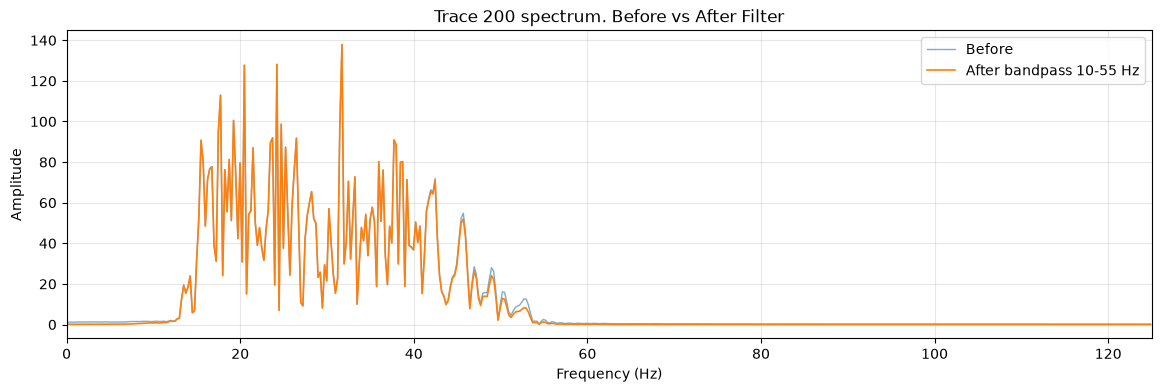

In [8]:
#Verify the filter worked : before/ after FFT of the same trace comparison

trace_filt = traces_filt[trace_idx]

spectrum_filt = np.abs(rfft(trace_filt))

plt.figure(figsize=(14,4))
plt.plot(freqs, spectrum, lw=1.0, label="Before", alpha=0.6)
plt.plot(freqs, spectrum_filt, lw=1.2, label="After bandpass 10-55 Hz")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title(f"Trace {trace_idx} spectrum. Before vs After Filter")
plt.xlim(0,125)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Observation:** before/after spectra are almost indistinguishable. Shows that the data was already band-limited. Bandpass filtering did almost nothing because there was nothing outside 10-55 Hz to remove. This is expected for well-processed data.

## Verifying filter behavior with synthetic noise

To prove the filter actually works, I inject a 2 Hz drift (below the band), a 90 Hz hiss (above the band), and random white noise into one trace, then perform the bandpass again.

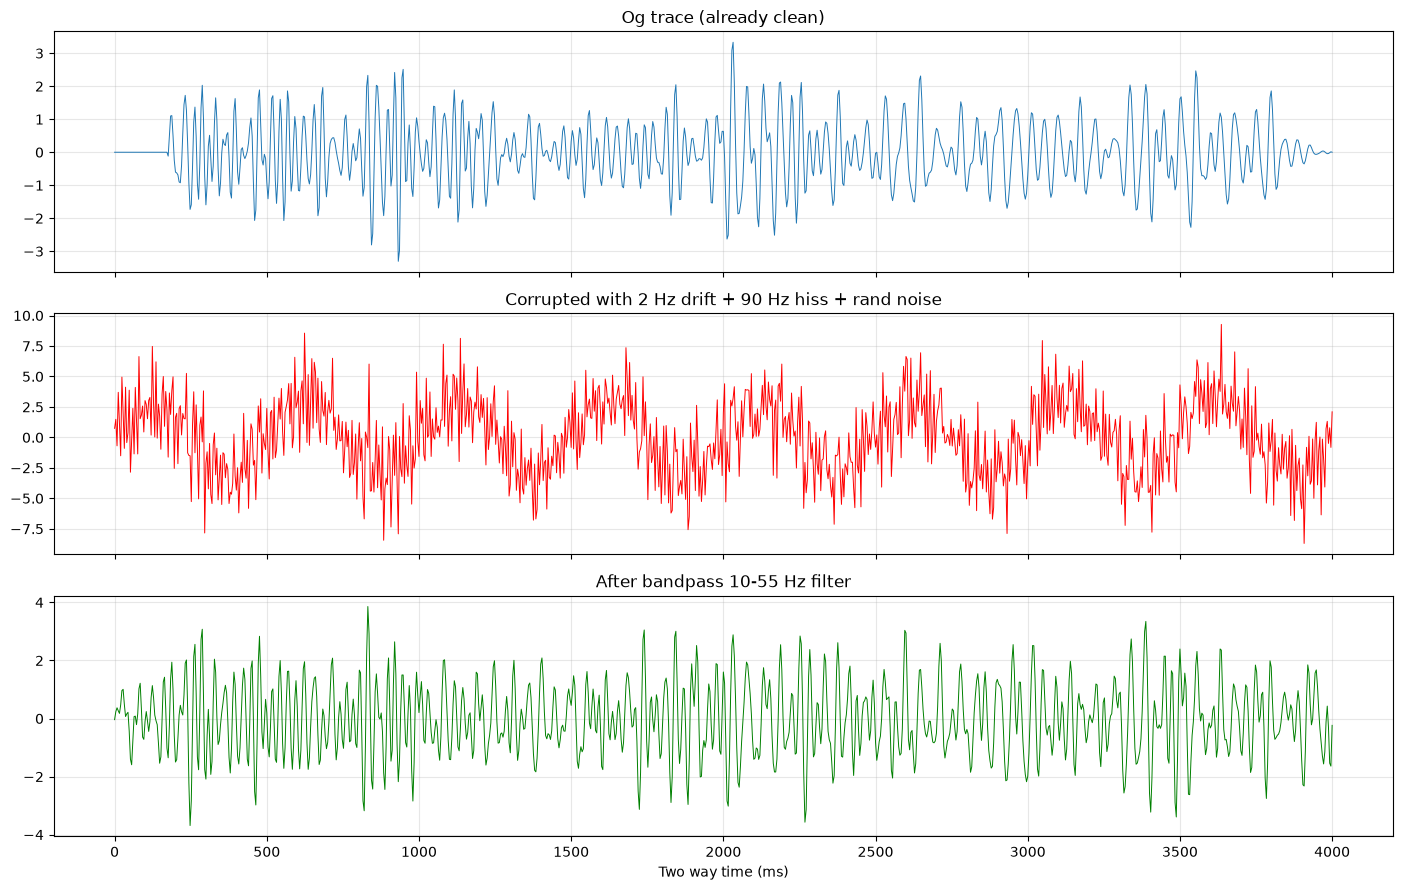

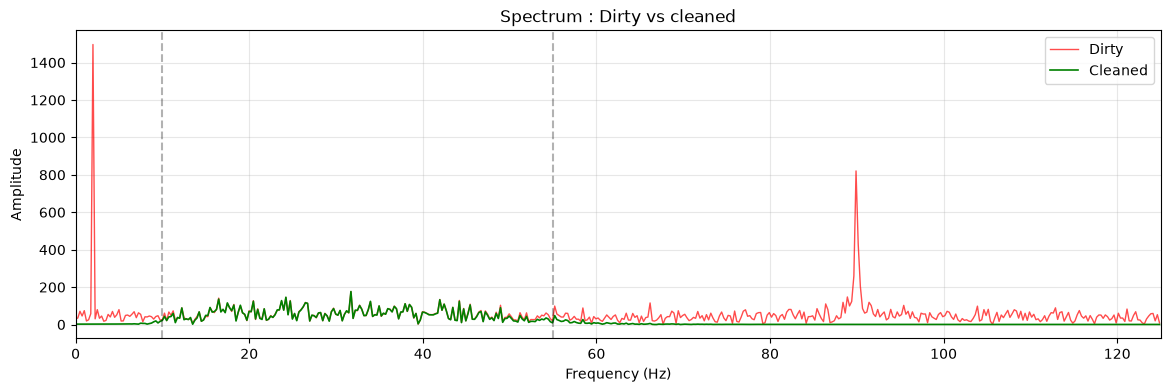

In [9]:
#Prove the filter actually works. Inject synthetic noise and clean it out

np.random.seed(42)
t_sec = np.arange(n_samples) * dt_s

#Low-freq drift (2 Hz - below our band)
drift = 3.0 * np.sin(2*np.pi*2*t_sec)

#High-freq hiss (90 Hz tone + white noise - above our band)
hiss = 2.0 * np.sin(2*np.pi*90*t_sec) + 1.5 * np.random.randn(n_samples)

trace_dirty = trace + drift + hiss
trace_cleaned = bandpass(trace_dirty, lowcut=10, highcut=55, fs=fs)

#  ----- Waveform comparison -------

fig, axes = plt.subplots(3,1,figsize=(14,9), sharex=True)
axes[0].plot(time_ms, trace, lw = 0.7)
axes[0].set_title("Og trace (already clean)")
axes[0].grid(alpha=0.3)

axes[1].plot(time_ms, trace_dirty, lw=0.7, color="red")
axes[1].set_title("Corrupted with 2 Hz drift + 90 Hz hiss + rand noise")
axes[1].grid(alpha=0.3)

axes[2].plot(time_ms, trace_cleaned, lw=0.7, color="green")
axes[2].set_title("After bandpass 10-55 Hz filter")
axes[2].set_xlabel("Two way time (ms)")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# -- Spectrum Comparison ---

spectrum_dirty = np.abs(rfft(trace_dirty))
spectrum_cleaned = np.abs(rfft(trace_cleaned))

plt.figure(figsize=(14,4))
plt.plot(freqs, spectrum_dirty, lw=1.0, label="Dirty", color="red", alpha=0.7)
plt.plot(freqs, spectrum_cleaned, lw=1.2, label="Cleaned", color="green")
plt.axvline(10, color="black", ls="--", alpha=0.3)
plt.axvline(55, color="black", ls="--", alpha=0.3)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Spectrum : Dirty vs cleaned")
plt.xlim(0,125)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Why doesnt the green (cleaned) trace exactly match the blue og trace?
# Bc it only removes noise OUTSIDE of 10-55 Hz band. Anything inside stays

**Result:** the 2 Hz and 90 Hz spikes are cleanly removed from the spectrum. In-band signal is preserved. Residual random noise within 10-55 Hz survives because the filter cannot differntiate in-band signal from in-band noise. Removing it would require spatial filtering or other techniques.

## Phase 3 - Envelope attribute (Hilbert transform)

The envelope is the "magnitude over time" of a signal, independent of its sign. useful because reflection polarity depends on physics detail don't affect reflection location. Collapsing polarity (absolute it) gives a cleaner map of where energy returned.

Computed via Hilbert transform: the signal paired with its 90 deg shifted version forms a complex-valued signal. Its absolute value is the envelope.

In [10]:
# Compute Envelope for every trace
# Envelope : smooth outline that wraps around all the wiggles. The loudness over time, independent of whether each indiv wiggle is +ve or -ve
# Why useful : In a raw trace, a strong reflection might peak +2.5, an equally strong next to it might peak -2.5
# So the envelope treats it like "abs value". It only cares about magnitude
# Result : a cleaner picture of WHERE reflections are , not what their polarity are

# How it's done : Hilbert transform, it shifts every frq compoennt by 90 deg. Combine the original signal with Hilbert, then take the magnitude
# We get envelope

from scipy.signal import hilbert

envelope = np.abs(hilbert(traces_filt, axis =-1))

print (f"Envelope shape: {envelope.shape}")
print (f"Envelope range: {envelope.min():.2f} to {envelope.max():.2f}")

Envelope shape: (390, 1001)
Envelope range: 0.00 to 6.81


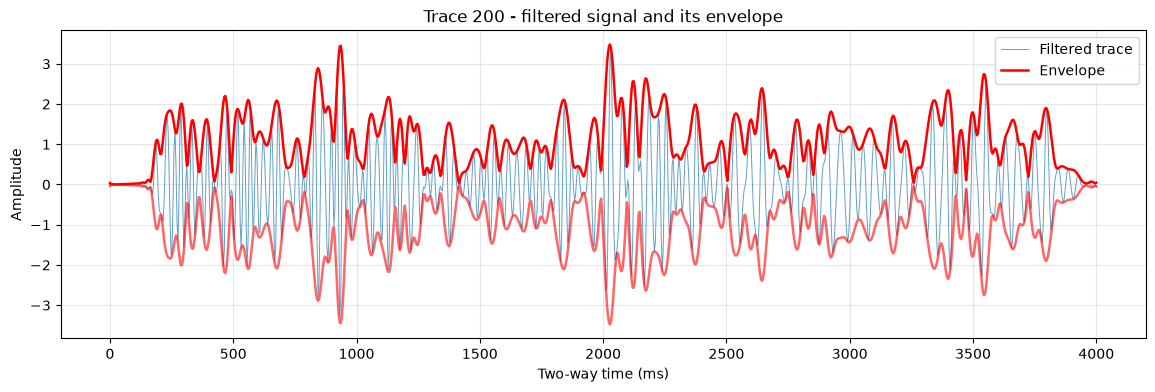

In [11]:
# Verify on one trace by overlaying envelope on the signal

plt.figure(figsize=(14,4))
plt.plot(time_ms, traces_filt[trace_idx], lw=0.7, alpha=0.7, label="Filtered trace")
plt.plot(time_ms, envelope[trace_idx], lw=1.8, color="red", label="Envelope")
plt.plot(time_ms, -envelope[trace_idx], lw=1.8, color="red", alpha=0.6)
plt.xlabel("Two-way time (ms)")
plt.ylabel("Amplitude")
plt.title(f"Trace {trace_idx} - filtered signal and its envelope")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Final comparison : raw, filtered & envelope 

Three-panel side by side of the same 2D section. The envelope panel uses the `hot` colormap because envelope is strictly positive. Bright = strong reflection energy, dark = quiet zones.

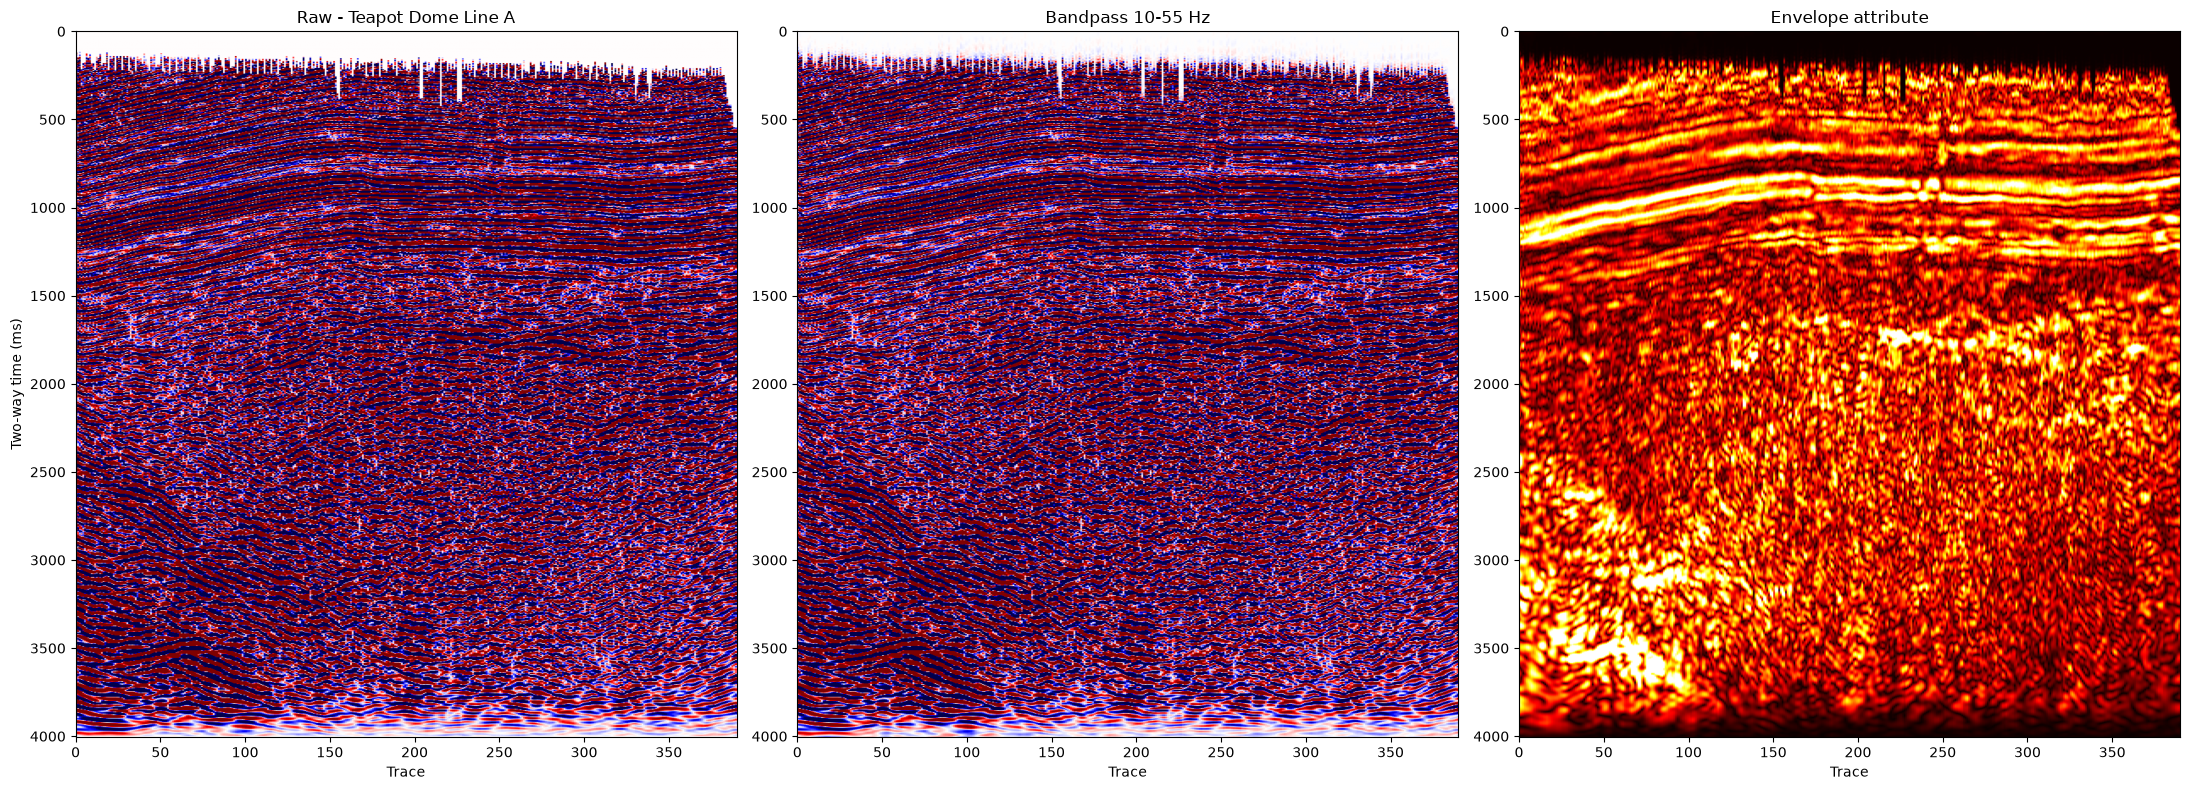

In [12]:
# 3-panel 2D section comparison

section_raw = traces.T
section_filt = traces_filt.T
section_env = envelope.T

vm = 0.5 * np.std(section_filt)   #the ratio controls how tight the clip is. The lower the number (0.5), more pixels at saturated colors, high contrast.
vm_env = np.percentile(section_env, 98) #98% because top 2% is usually a handful of extreme outliers 

fig, axes = plt.subplots(1,3, figsize=(22,8))

axes[0].imshow(section_raw, cmap="seismic", vmin=-vm, vmax=vm, aspect="auto", 
               extent=[0, section_raw.shape[1], section_raw.shape[0]*sample_rate_ms, 0])
axes[0].set_title("Raw - Teapot Dome Line A")
axes[0].set_xlabel("Trace")
axes[0].set_ylabel("Two-way time (ms)")

axes[1].imshow(section_filt, cmap="seismic", vmin=-vm, vmax=vm, aspect="auto",
               extent=[0, section_filt.shape[1], section_filt.shape[0]*sample_rate_ms, 0])
axes[1].set_title("Bandpass 10-55 Hz")
axes[1].set_xlabel("Trace")

axes[2].imshow(section_env, cmap="hot", vmin=0, vmax=vm_env, aspect="auto",
               extent=[0, section_env.shape[1], section_env.shape[0]*sample_rate_ms, 0])
axes[2].set_title("Envelope attribute")
axes[2].set_xlabel("Trace")

plt.tight_layout()

# save the comparison result
import os
os.makedirs("images", exist_ok=True)
plt.savefig("images/section_comparison.png", dpi=150, bbox_inches="tight")

plt.show()

## Conclusions 

- Successfully loaded, visualised, and processed a real 2D seismic SEG-Y file from end-to-end with no prior seismic experience.
- Identified frequency content: dominant 30-35 Hz , usable band ~10-55 Hz.
- Designed and validated a Butterworth bandpass filter, proved correctness via synthetic noise injection when the native data turned out to be already band-limited.
- Computed the envelope attribute - the most common first attribute in seismic interpretation, and compared it against raw & filtered sections.

## What I could do next given more time

- **Instantaneous frequency** (the other main Hilbert attribute). This can help flag gas-bearing areas.
- **Horizon picking** : auto-track one of the bright reflections across the whole 2D line.
- Load a 3D volume and extract inline / crossline / time-slice views.
- Combine multiple attributes for seismic facies classification

## References

- Teapot Dome dataset : Rocky Mountain Oilfield Testing Centre (RMOTC) / US Department of Energy, public domain.
- Mirror used : softwareunderground/TeapotDome (https://github.com/softwareunderground/TeapotDome/blob/master/source/2D_Seismic/NormalizedMigrated_segy/lineA.sgy)
- `segyio` by Equinor
- `scipy.signal`. Butterworth filter, `filtfilt`, Hilbert transform